# RMSF Fluctuation Comparison: MUC2 Glycans vs No Glycans

Plots mean ± std of RMSF across 3 runs for each system on the same graph.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-darkgrid")

output_dir = "/home/computer2/analysis_simulations/analysis/plots"
os.makedirs(output_dir, exist_ok=True)

## Load RMSF Data

In [2]:
# MUC2 Glycans (3 runs)
df_g1 = pd.read_csv("/home/computer2/analysis_simulations/analysis/analysis_ambernew_system/rmsf.dat",
                    sep=r"\s+", skiprows=1, names=["Residue", "RMSF"])
df_g2 = pd.read_csv("/home/computer2/analysis_simulations/analysis/analysis_ambernew_system2/rmsf_2.dat",
                    sep=r"\s+", skiprows=1, names=["Residue", "RMSF"])
df_g3 = pd.read_csv("/home/computer2/analysis_simulations/analysis/analysis_ambernew_system3/rmsf_3.dat",
                    sep=r"\s+", skiprows=1, names=["Residue", "RMSF"])

# MUC2 No Glycans (3 runs)
df_ng1 = pd.read_csv("/home/computer2/analysis_simulations/analysis/analysis_muc2_noglycans/rmsf.dat",
                     sep=r"\s+", skiprows=1, names=["Residue", "RMSF"])
df_ng2 = pd.read_csv("/home/computer2/analysis_simulations/analysis/analysis_muc2_noglycans1/rmsf_noglyc_1.dat",
                     sep=r"\s+", skiprows=1, names=["Residue", "RMSF"])
df_ng3 = pd.read_csv("/home/computer2/analysis_simulations/analysis/analysis_muc2_noglycans3/rmsf3_noglyc.dat",
                     sep=r"\s+", skiprows=1, names=["Residue", "RMSF"])

print("Glycans    - Run1:", df_g1.shape, " Run2:", df_g2.shape, " Run3:", df_g3.shape)
print("No Glycans - Run1:", df_ng1.shape, " Run2:", df_ng2.shape, " Run3:", df_ng3.shape)

Glycans    - Run1: (2265, 2)  Run2: (2265, 2)  Run3: (2265, 2)
No Glycans - Run1: (2265, 2)  Run2: (2265, 2)  Run3: (2265, 2)


## Compute Mean ± Std

In [3]:
# MUC2 Glycans mean ± std
rmsf_g = pd.concat([
    df_g1.set_index("Residue")["RMSF"],
    df_g2.set_index("Residue")["RMSF"],
    df_g3.set_index("Residue")["RMSF"]
], axis=1, keys=["Run1", "Run2", "Run3"])
mean_g = rmsf_g.mean(axis=1)
std_g  = rmsf_g.std(axis=1)
res_g  = mean_g.index

# MUC2 No Glycans mean ± std
rmsf_ng = pd.concat([
    df_ng1.set_index("Residue")["RMSF"],
    df_ng2.set_index("Residue")["RMSF"],
    df_ng3.set_index("Residue")["RMSF"]
], axis=1, keys=["Run1", "Run2", "Run3"])
mean_ng = rmsf_ng.mean(axis=1)
std_ng  = rmsf_ng.std(axis=1)
res_ng  = mean_ng.index

print(f"Glycans:    {len(res_g)} residues, mean RMSF = {mean_g.mean():.3f} A")
print(f"No Glycans: {len(res_ng)} residues, mean RMSF = {mean_ng.mean():.3f} A")

Glycans:    2265 residues, mean RMSF = 55.021 A
No Glycans: 2265 residues, mean RMSF = 48.203 A


## Plot Comparison

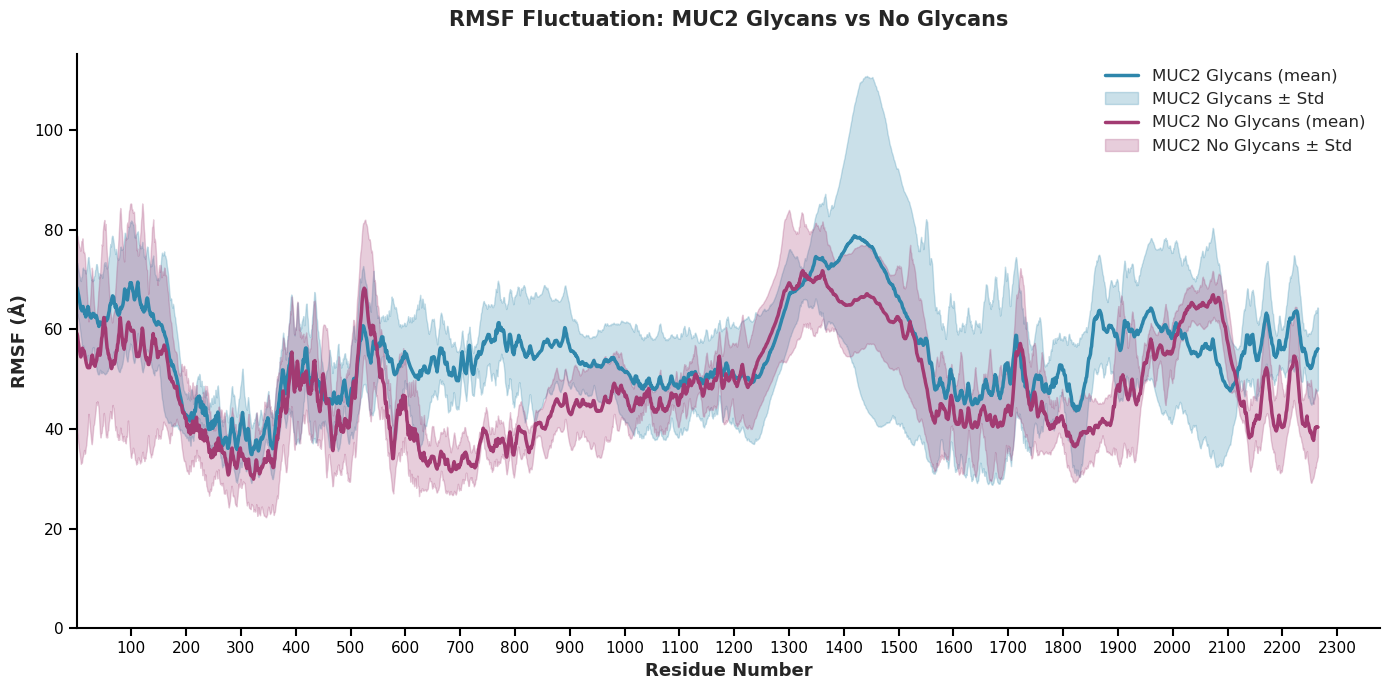

Saved: /home/computer2/analysis_simulations/analysis/plots/rmsf_fluctuation_glycans_vs_noglycans.png


In [4]:
fig, ax = plt.subplots(figsize=(14, 7), dpi=100)

# MUC2 Glycans
ax.plot(res_g, mean_g, linewidth=2.5, color="#2E86AB", label="MUC2 Glycans (mean)")
ax.fill_between(res_g, mean_g - std_g, mean_g + std_g,
                alpha=0.25, color="#2E86AB", label="MUC2 Glycans ± Std")

# MUC2 No Glycans
ax.plot(res_ng, mean_ng, linewidth=2.5, color="#A23B72", label="MUC2 No Glycans (mean)")
ax.fill_between(res_ng, mean_ng - std_ng, mean_ng + std_ng,
                alpha=0.25, color="#A23B72", label="MUC2 No Glycans ± Std")

# Axes labels & title
ax.set_xlabel("Residue Number", fontsize=13, fontweight="bold")
ax.set_ylabel("RMSF (Å)", fontsize=13, fontweight="bold")
ax.set_title("RMSF Fluctuation: MUC2 Glycans vs No Glycans", fontsize=15, fontweight="bold", pad=20)

# Ticks and limits
max_res = max(res_g.max(), res_ng.max())
min_res = min(res_g.min(), res_ng.min())
ax.set_xticks(np.arange(0, max_res + 100, 100))
ax.set_xlim(left=min_res)
ax.set_ylim(bottom=0)

# Grid and styling
ax.grid(True, alpha=0.3, linestyle="--", linewidth=0.5)
ax.set_facecolor("white")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(True)
ax.spines["left"].set_color("black")
ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_visible(True)
ax.spines["bottom"].set_color("black")
ax.spines["bottom"].set_linewidth(1.5)
ax.tick_params(axis="both", which="major", labelsize=11, length=6, width=1.5, direction="out", colors="black")
ax.legend(fontsize=12, loc="best")

plt.tight_layout()
out = os.path.join(output_dir, "rmsf_fluctuation_glycans_vs_noglycans.png")
plt.savefig(out, dpi=800, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

In [5]:
import matplotlib.ticker as ticker

CLR_NOG = "#A23B72"
CLR_GLY = "#2E86AB"
CLR_EXT = "#F18F01"

EXT_BASE = "/home/computer2/analysis_simulations/analysis/muc2_extensiveglycans/"

df_ext1 = pd.read_csv(EXT_BASE + "rmsf_extensiveglycans1.dat",
                      sep=r"\s+", skiprows=1, names=["Residue", "RMSF"])
df_ext2 = pd.read_csv(EXT_BASE + "rmsf_extensiveglycans2.dat",
                      sep=r"\s+", skiprows=1, names=["Residue", "RMSF"])
df_ext3 = pd.read_csv(EXT_BASE + "rmsf_extensiveglycans3.dat",
                      sep=r"\s+", skiprows=1, names=["Residue", "RMSF"])

rmsf_ext = pd.concat([
    df_ext1.set_index("Residue")["RMSF"],
    df_ext2.set_index("Residue")["RMSF"],
    df_ext3.set_index("Residue")["RMSF"],
], axis=1, keys=["Run1", "Run2", "Run3"])
mean_ext = rmsf_ext.mean(axis=1)
std_ext  = rmsf_ext.std(axis=1)
res_ext  = mean_ext.index

print(f"Ext. Glycosylated: {len(res_ext)} residues")
print(f"Residue range: {res_ext.min():.0f} to {res_ext.max():.0f}")
print(f"Mean RMSF = {mean_ext.mean():.3f} A  |  Max = {mean_ext.max():.3f} A")


Ext. Glycosylated: 2265 residues
Residue range: 1 to 2265
Mean RMSF = 39.372 A  |  Max = 62.007 A


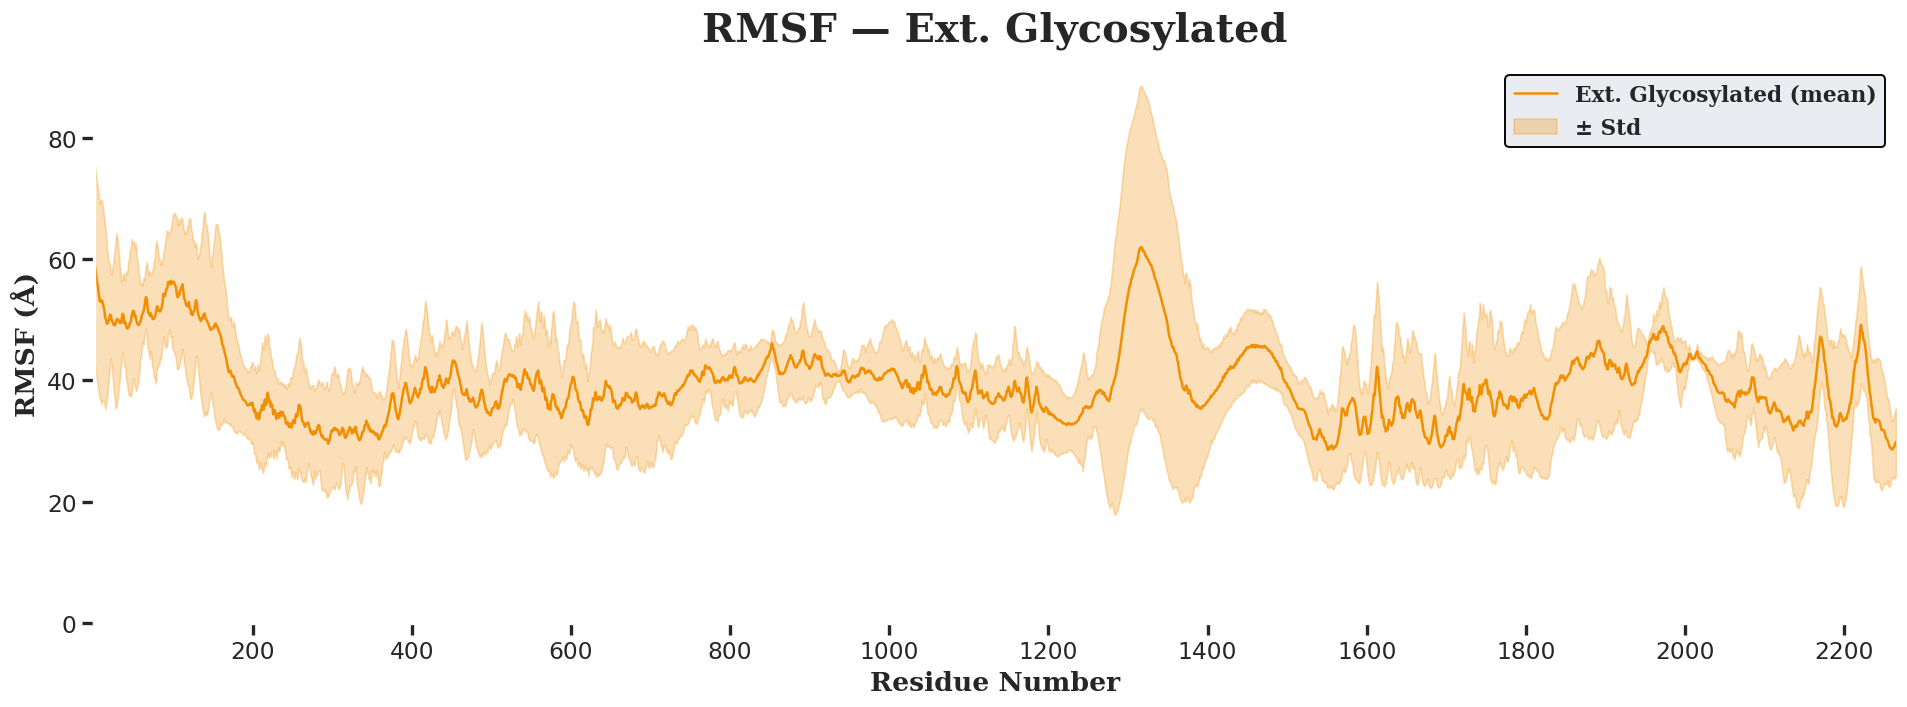

Saved: /home/computer2/analysis_simulations/analysis/plots/rmsf_ext_glycosylated.png


In [6]:
fig, ax = plt.subplots(figsize=(16, 6), dpi=120)
fig.set_facecolor("white")

ax.plot(res_ext, mean_ext, linewidth=1.5, color=CLR_EXT,
        label="Ext. Glycosylated (mean)")
ax.fill_between(res_ext, mean_ext - std_ext, mean_ext + std_ext,
                alpha=0.28, color=CLR_EXT, label="\u00b1 Std")

ax.set_xlabel("Residue Number", fontsize=16, fontname="DejaVu Serif", fontweight="bold")
ax.set_ylabel("RMSF (\u00c5)", fontsize=16, fontname="DejaVu Serif", fontweight="bold")
ax.set_title("RMSF \u2014 Ext. Glycosylated", fontsize=24,
             fontname="DejaVu Serif", fontweight="bold", pad=14)
ax.set_xlim(res_ext.min(), res_ext.max())
ax.set_ylim(bottom=0)
ax.xaxis.set_major_locator(ticker.MultipleLocator(200))
ax.set_facecolor("white")
ax.spines["top"].set_visible(False);  ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(2.0); ax.spines["bottom"].set_linewidth(2.0)
ax.tick_params(labelsize=14, length=7, width=2.0, direction="out")
leg = ax.legend(fontsize=13, frameon=True, framealpha=0.95, edgecolor="black",
                prop={"family": "DejaVu Serif", "size": 13, "weight": "bold"})
leg.get_frame().set_linewidth(1.2)
plt.tight_layout()
out = os.path.join(output_dir, "rmsf_ext_glycosylated.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")


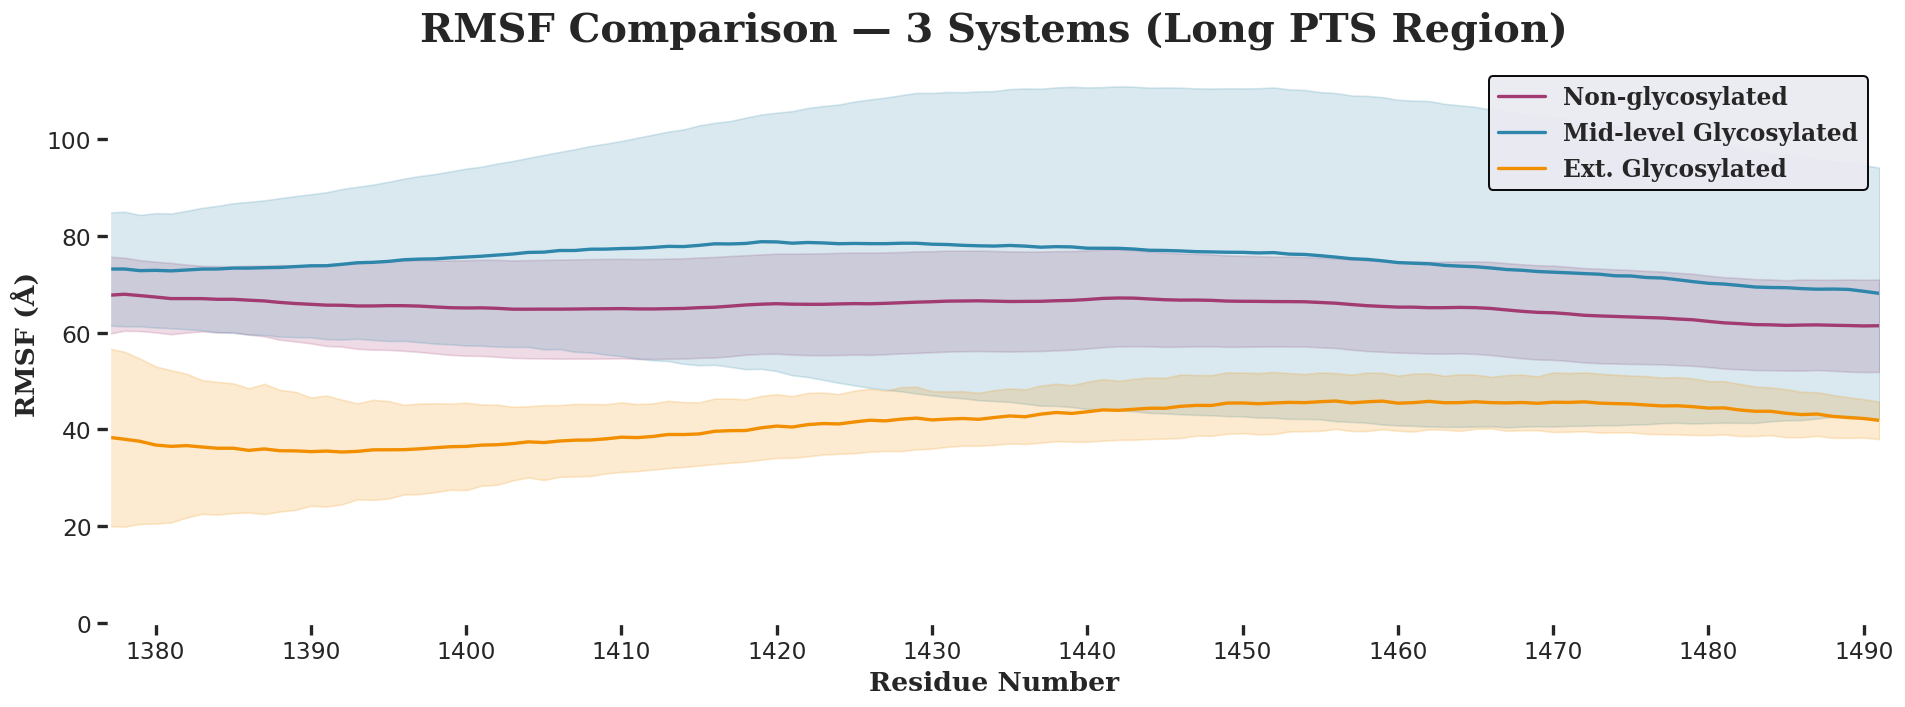

Saved: /home/computer2/analysis_simulations/analysis/plots/rmsf_3sys_comparison.png


In [7]:
fig, ax = plt.subplots(figsize=(16, 6), dpi=120)
fig.set_facecolor("white")

systems = [
    (res_ng,  mean_ng,  std_ng,  CLR_NOG, "Non-glycosylated"),
    (res_g,   mean_g,   std_g,   CLR_GLY, "Mid-level Glycosylated"),
    (res_ext, mean_ext, std_ext, CLR_EXT, "Ext. Glycosylated"),
]

for x, mean, std, clr, lbl in systems:
    mask = (x >= 1377) & (x <= 1491)
    ax.plot(x[mask], mean[mask], linewidth=2.0, color=clr, label=lbl)
    ax.fill_between(x[mask], (mean - std)[mask], (mean + std)[mask],
                    alpha=0.18, color=clr)

ax.set_xlabel("Residue Number", fontsize=16, fontname="DejaVu Serif", fontweight="bold")
ax.set_ylabel("RMSF (\u00c5)", fontsize=16, fontname="DejaVu Serif", fontweight="bold")
ax.set_title("RMSF Comparison \u2014 3 Systems (Long PTS Region)", fontsize=24,
             fontname="DejaVu Serif", fontweight="bold", pad=14)
ax.set_xlim(1377, 1491)
ax.set_ylim(bottom=0)
ax.xaxis.set_major_locator(ticker.MultipleLocator(10))
ax.set_facecolor("white")
ax.spines["top"].set_visible(False);  ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(2.0); ax.spines["bottom"].set_linewidth(2.0)
ax.tick_params(labelsize=14, length=7, width=2.0, direction="out")
leg = ax.legend(fontsize=14, frameon=True, framealpha=0.95, edgecolor="black",
                prop={"family": "DejaVu Serif", "size": 14, "weight": "bold"},
                loc="upper right")
leg.get_frame().set_linewidth(1.2)
plt.tight_layout()
out = os.path.join(output_dir, "rmsf_3sys_comparison.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")


Long PTS residues compared: 115
Mean difference (Ext - Mid): -33.536 A
Max increase in Ext:  -25.598 A  at residue 1484
Max decrease in Ext:  -39.448 A  at residue 1408


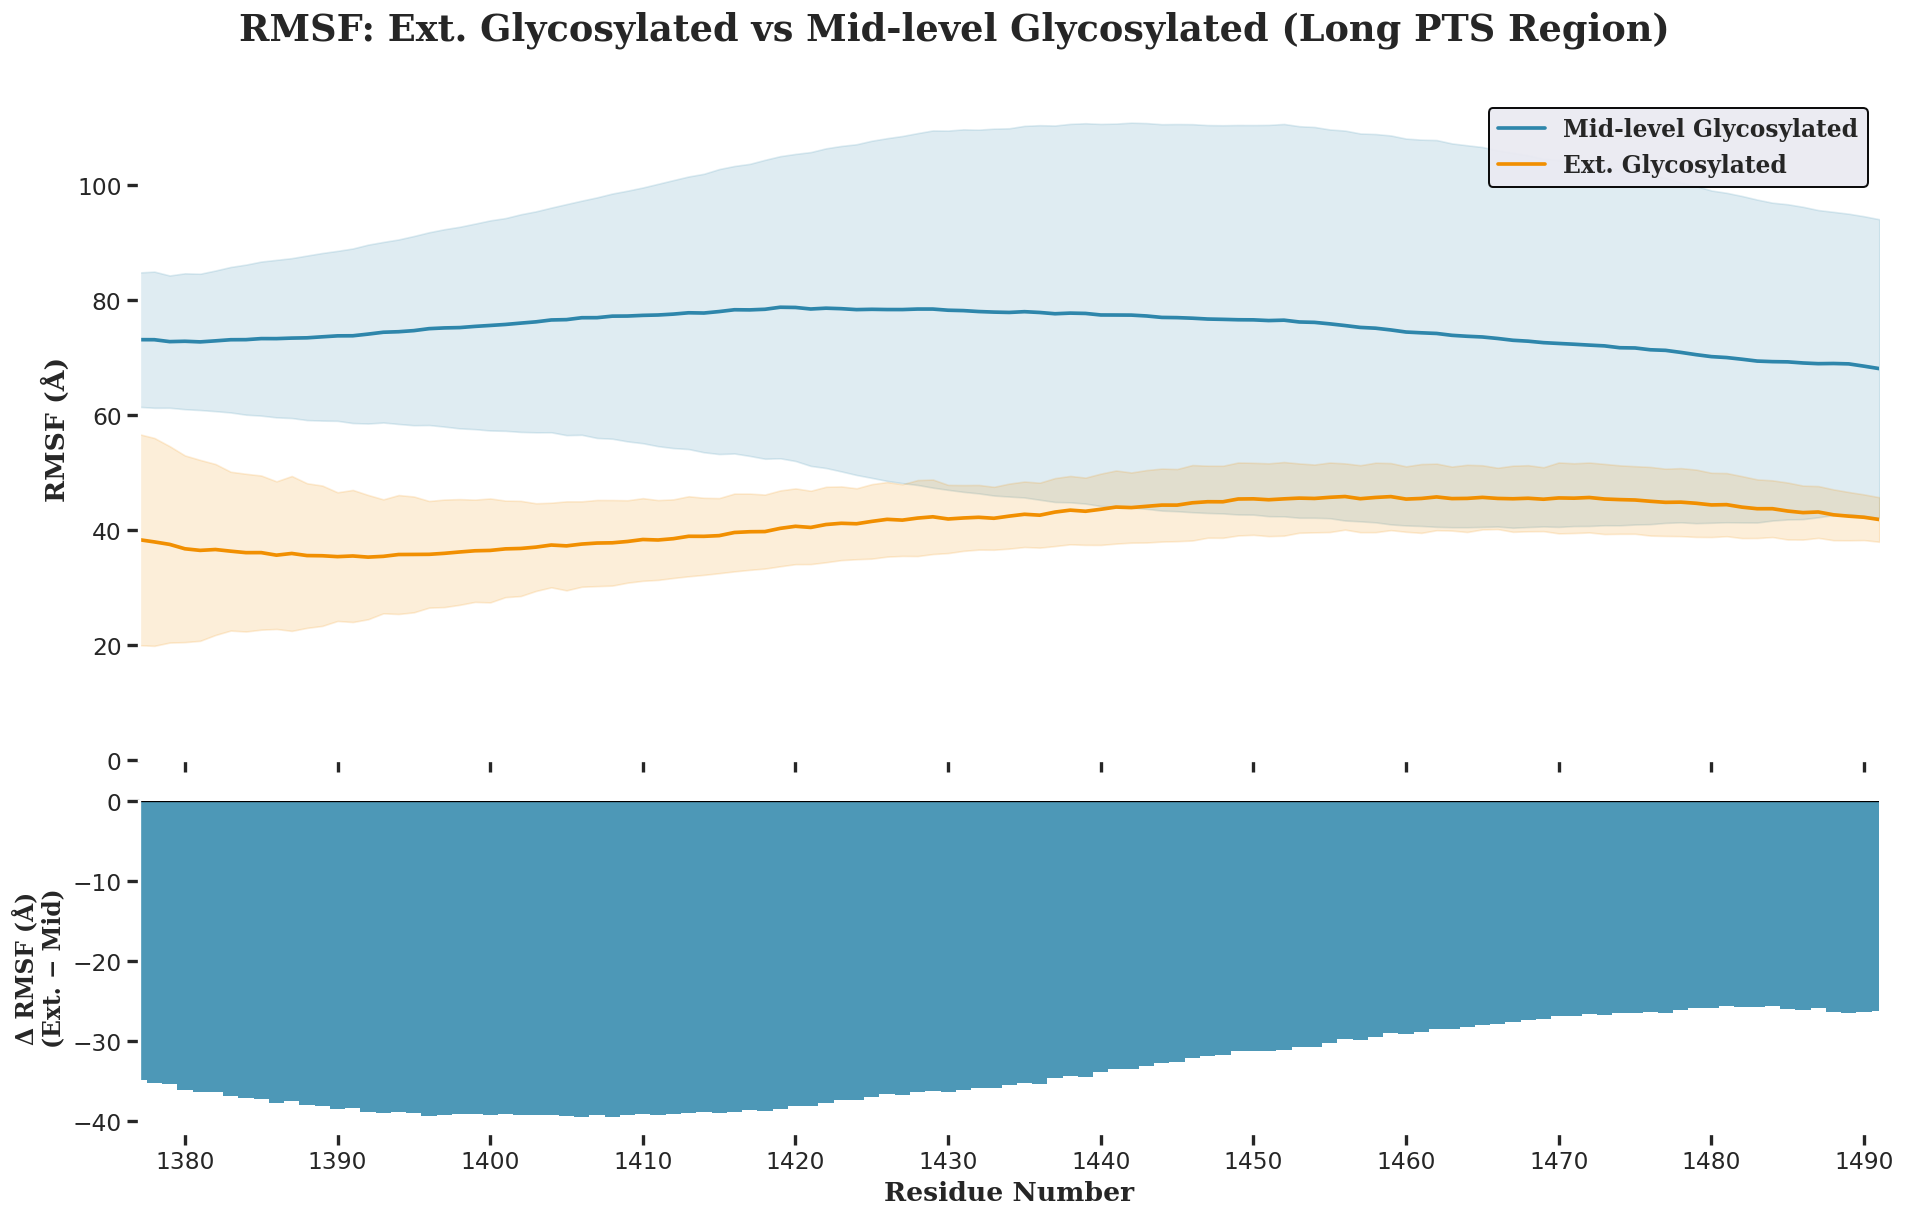

Saved: /home/computer2/analysis_simulations/analysis/plots/rmsf_diff_ext_vs_gly.png


In [8]:
import pandas as pd

CLR_GLY = "#2E86AB"
CLR_EXT = "#F18F01"

# Extract Long PTS region (1377-1491) for both systems
pts_mask_g   = (res_g   >= 1377) & (res_g   <= 1491)
pts_mask_ext = (res_ext >= 1377) & (res_ext <= 1491)

mean_g_pts   = mean_g[pts_mask_g]
mean_ext_pts = mean_ext[pts_mask_ext]

# Align on integer residue number
idx_g   = mean_g_pts.index.astype(int)
idx_ext = mean_ext_pts.index.astype(int)
shared  = sorted(set(idx_g) & set(idx_ext))

mean_g_aligned   = pd.Series(mean_g_pts.values,   index=idx_g  ).reindex(shared)
mean_ext_aligned = pd.Series(mean_ext_pts.values, index=idx_ext).reindex(shared)
diff = mean_ext_aligned - mean_g_aligned

print(f"Long PTS residues compared: {len(shared)}")
print(f"Mean difference (Ext - Mid): {diff.mean():.3f} A")
print(f"Max increase in Ext:  {diff.max():.3f} A  at residue {diff.idxmax()}")
print(f"Max decrease in Ext:  {diff.min():.3f} A  at residue {diff.idxmin()}")

# Reindex std bands onto shared index
std_g_aligned   = pd.Series(std_g[pts_mask_g].values,     index=idx_g  ).reindex(shared)
std_ext_aligned = pd.Series(std_ext[pts_mask_ext].values, index=idx_ext).reindex(shared)

fig, axes = plt.subplots(2, 1, figsize=(16, 10), dpi=120,
                         gridspec_kw={"height_ratios": [2, 1]}, sharex=True)
fig.set_facecolor("white")

# Top: overlay both systems
ax = axes[0]
ax.plot(shared, mean_g_aligned,   linewidth=2.2, color=CLR_GLY, label="Mid-level Glycosylated")
ax.plot(shared, mean_ext_aligned, linewidth=2.2, color=CLR_EXT, label="Ext. Glycosylated")
ax.fill_between(shared, mean_g_aligned - std_g_aligned,   mean_g_aligned + std_g_aligned,
                alpha=0.15, color=CLR_GLY)
ax.fill_between(shared, mean_ext_aligned - std_ext_aligned, mean_ext_aligned + std_ext_aligned,
                alpha=0.15, color=CLR_EXT)
ax.set_ylabel("RMSF (\u00c5)", fontsize=16, fontname="DejaVu Serif", fontweight="bold")
ax.set_ylim(bottom=0)
ax.set_facecolor("white")
ax.spines["top"].set_visible(False);  ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(2.0); ax.spines["bottom"].set_linewidth(2.0)
ax.tick_params(labelsize=14, length=7, width=2.0, direction="out")
leg = ax.legend(fontsize=14, frameon=True, framealpha=0.95, edgecolor="black",
                prop={"family": "DejaVu Serif", "size": 14, "weight": "bold"},
                loc="upper right")
leg.get_frame().set_linewidth(1.2)

# Bottom: difference bar
ax2 = axes[1]
colors = [CLR_EXT if v > 0 else CLR_GLY for v in diff.values]
ax2.bar(shared, diff.values, color=colors, width=1.0, alpha=0.85)
ax2.axhline(0, color="black", linewidth=1.4)
ax2.set_xlabel("Residue Number", fontsize=16, fontname="DejaVu Serif", fontweight="bold")
ax2.set_ylabel("\u0394 RMSF (\u00c5)\n(Ext. \u2212 Mid)", fontsize=14,
               fontname="DejaVu Serif", fontweight="bold")
ax2.set_facecolor("white")
ax2.spines["top"].set_visible(False);  ax2.spines["right"].set_visible(False)
ax2.spines["left"].set_linewidth(2.0); ax2.spines["bottom"].set_linewidth(2.0)
ax2.tick_params(labelsize=14, length=7, width=2.0, direction="out")
ax2.set_xlim(1377, 1491)
ax2.xaxis.set_major_locator(ticker.MultipleLocator(10))

fig.suptitle("RMSF: Ext. Glycosylated vs Mid-level Glycosylated (Long PTS Region)",
             fontsize=22, fontname="DejaVu Serif", fontweight="bold", y=1.01)
plt.tight_layout()
out = os.path.join(output_dir, "rmsf_diff_ext_vs_gly.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")


Residues compared: 115
Mean RMSF  Non-glycosylated  : 65.278 A
Mean RMSF  Mid-level Glyc    : 74.975 A
Mean diff  (NonGlyc - Mid)   : -9.698 A
Max higher in NonGlyc: -5.162 A at residue 1379
Max higher in Mid-Glyc: -13.109 A at residue 1416


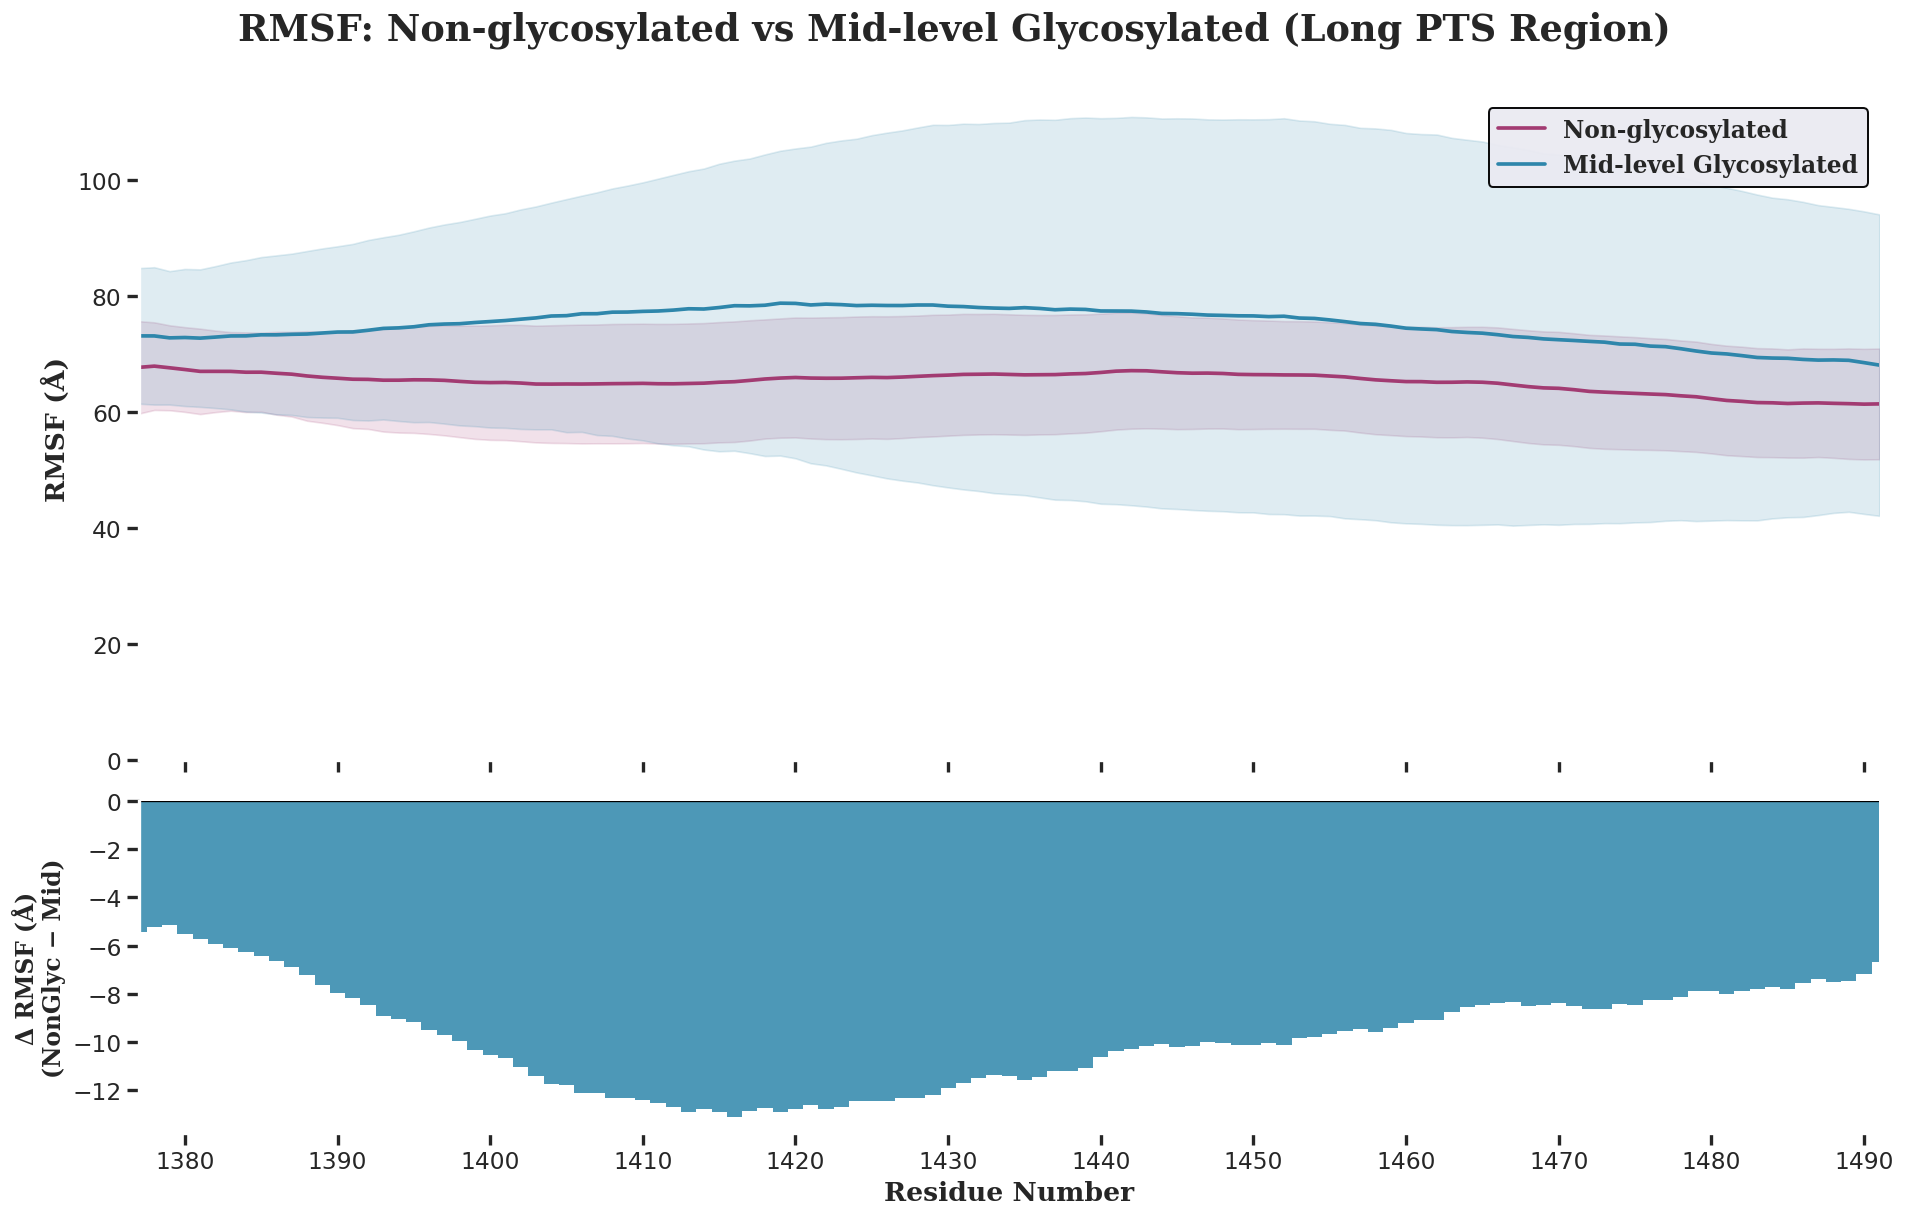

Saved: /home/computer2/analysis_simulations/analysis/plots/rmsf_diff_nog_vs_gly.png


In [9]:
import pandas as pd

CLR_NOG = "#A23B72"
CLR_GLY = "#2E86AB"

# Extract Long PTS region for both systems
pts_mask_ng = (res_ng >= 1377) & (res_ng <= 1491)
pts_mask_g  = (res_g  >= 1377) & (res_g  <= 1491)

mean_ng_pts = mean_ng[pts_mask_ng]
mean_g_pts  = mean_g[pts_mask_g]
std_ng_pts  = std_ng[pts_mask_ng]
std_g_pts   = std_g[pts_mask_g]

# Align on integer residue number
idx_ng = mean_ng_pts.index.astype(int)
idx_g  = mean_g_pts.index.astype(int)
shared = sorted(set(idx_ng) & set(idx_g))

mean_ng_a = pd.Series(mean_ng_pts.values, index=idx_ng).reindex(shared)
mean_g_a  = pd.Series(mean_g_pts.values,  index=idx_g ).reindex(shared)
std_ng_a  = pd.Series(std_ng_pts.values,  index=idx_ng).reindex(shared)
std_g_a   = pd.Series(std_g_pts.values,   index=idx_g ).reindex(shared)
diff_ng_g = mean_ng_a - mean_g_a   # positive = non-glyc more flexible

print(f"Residues compared: {len(shared)}")
print(f"Mean RMSF  Non-glycosylated  : {mean_ng_a.mean():.3f} A")
print(f"Mean RMSF  Mid-level Glyc    : {mean_g_a.mean():.3f} A")
print(f"Mean diff  (NonGlyc - Mid)   : {diff_ng_g.mean():.3f} A")
print(f"Max higher in NonGlyc: {diff_ng_g.max():.3f} A at residue {diff_ng_g.idxmax()}")
print(f"Max higher in Mid-Glyc: {diff_ng_g.min():.3f} A at residue {diff_ng_g.idxmin()}")

fig, axes = plt.subplots(2, 1, figsize=(16, 10), dpi=120,
                         gridspec_kw={"height_ratios": [2, 1]}, sharex=True)
fig.set_facecolor("white")

# Top: overlay both systems
ax = axes[0]
ax.plot(shared, mean_ng_a, linewidth=2.2, color=CLR_NOG, label="Non-glycosylated")
ax.plot(shared, mean_g_a,  linewidth=2.2, color=CLR_GLY, label="Mid-level Glycosylated")
ax.fill_between(shared, mean_ng_a - std_ng_a, mean_ng_a + std_ng_a, alpha=0.15, color=CLR_NOG)
ax.fill_between(shared, mean_g_a  - std_g_a,  mean_g_a  + std_g_a,  alpha=0.15, color=CLR_GLY)
ax.set_ylabel("RMSF (\u00c5)", fontsize=16, fontname="DejaVu Serif", fontweight="bold")
ax.set_ylim(bottom=0)
ax.set_facecolor("white")
ax.spines["top"].set_visible(False);  ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(2.0); ax.spines["bottom"].set_linewidth(2.0)
ax.tick_params(labelsize=14, length=7, width=2.0, direction="out")
leg = ax.legend(fontsize=14, frameon=True, framealpha=0.95, edgecolor="black",
                prop={"family": "DejaVu Serif", "size": 14, "weight": "bold"},
                loc="upper right")
leg.get_frame().set_linewidth(1.2)

# Bottom: difference bar
ax2 = axes[1]
colors = [CLR_NOG if v > 0 else CLR_GLY for v in diff_ng_g.values]
ax2.bar(shared, diff_ng_g.values, color=colors, width=1.0, alpha=0.85)
ax2.axhline(0, color="black", linewidth=1.4)
ax2.set_xlabel("Residue Number", fontsize=16, fontname="DejaVu Serif", fontweight="bold")
ax2.set_ylabel("\u0394 RMSF (\u00c5)\n(NonGlyc \u2212 Mid)", fontsize=14,
               fontname="DejaVu Serif", fontweight="bold")
ax2.set_facecolor("white")
ax2.spines["top"].set_visible(False);  ax2.spines["right"].set_visible(False)
ax2.spines["left"].set_linewidth(2.0); ax2.spines["bottom"].set_linewidth(2.0)
ax2.tick_params(labelsize=14, length=7, width=2.0, direction="out")
ax2.set_xlim(1377, 1491)
ax2.xaxis.set_major_locator(ticker.MultipleLocator(10))

fig.suptitle("RMSF: Non-glycosylated vs Mid-level Glycosylated (Long PTS Region)",
             fontsize=22, fontname="DejaVu Serif", fontweight="bold", y=1.01)
plt.tight_layout()
out = os.path.join(output_dir, "rmsf_diff_nog_vs_gly.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")


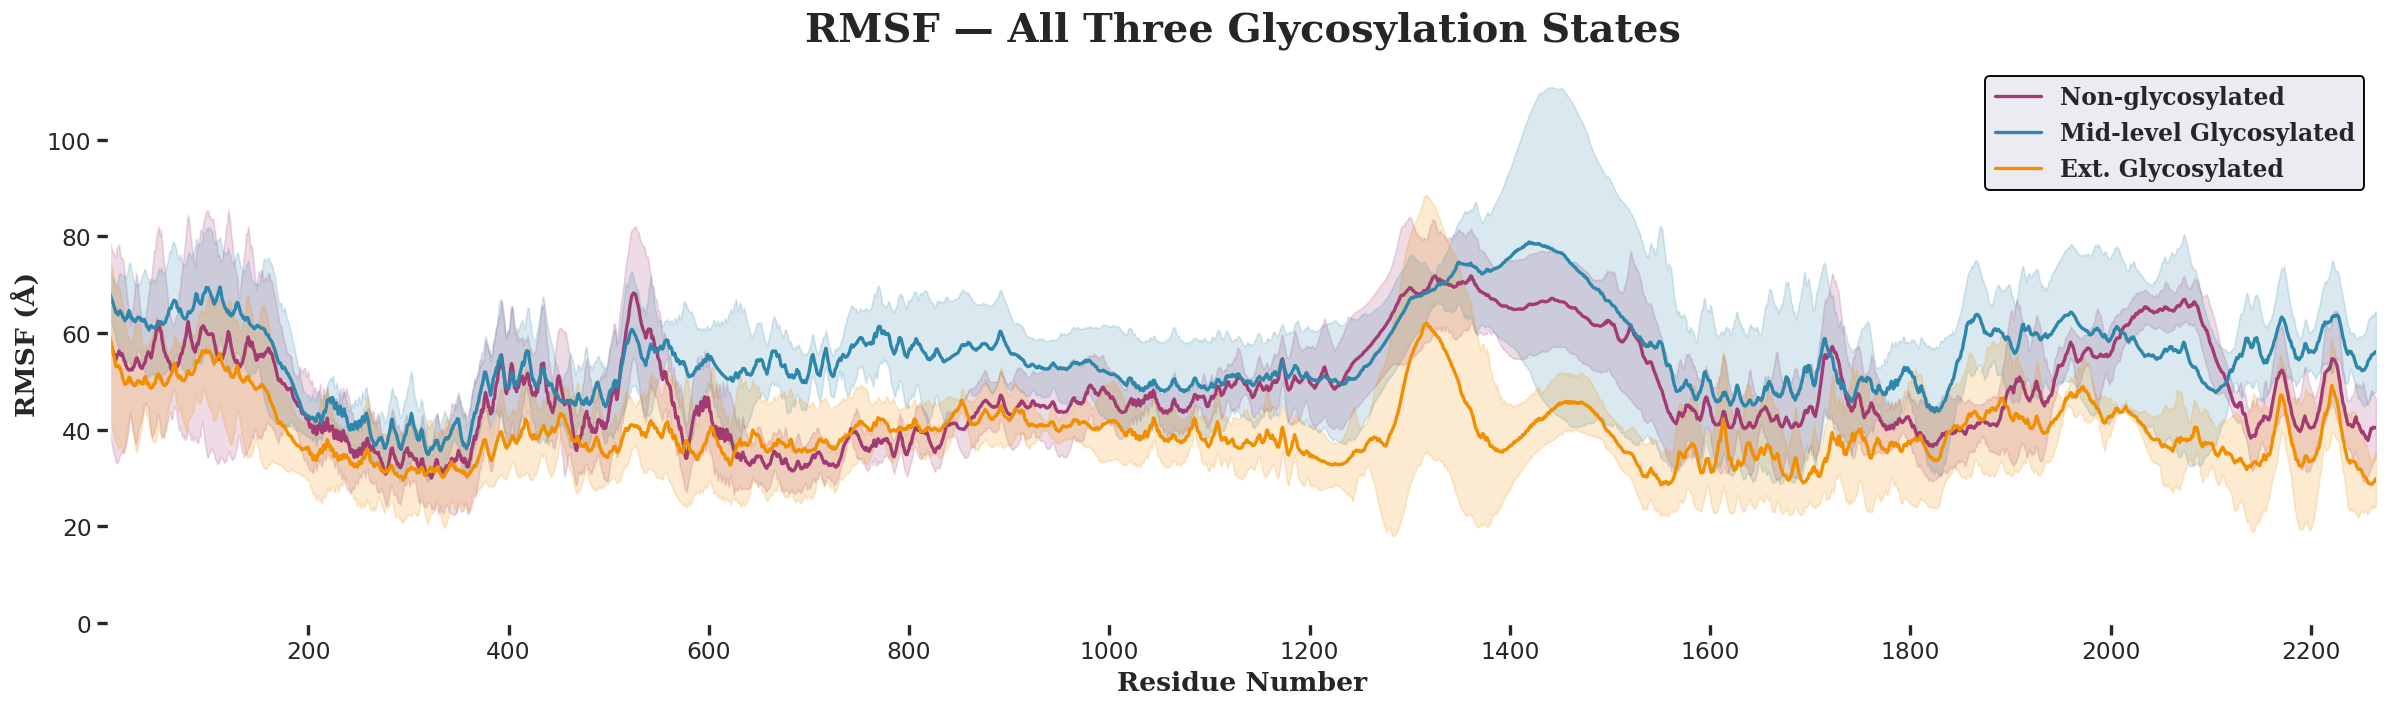

Saved: /home/computer2/analysis_simulations/analysis/plots/rmsf_3sys_full.png


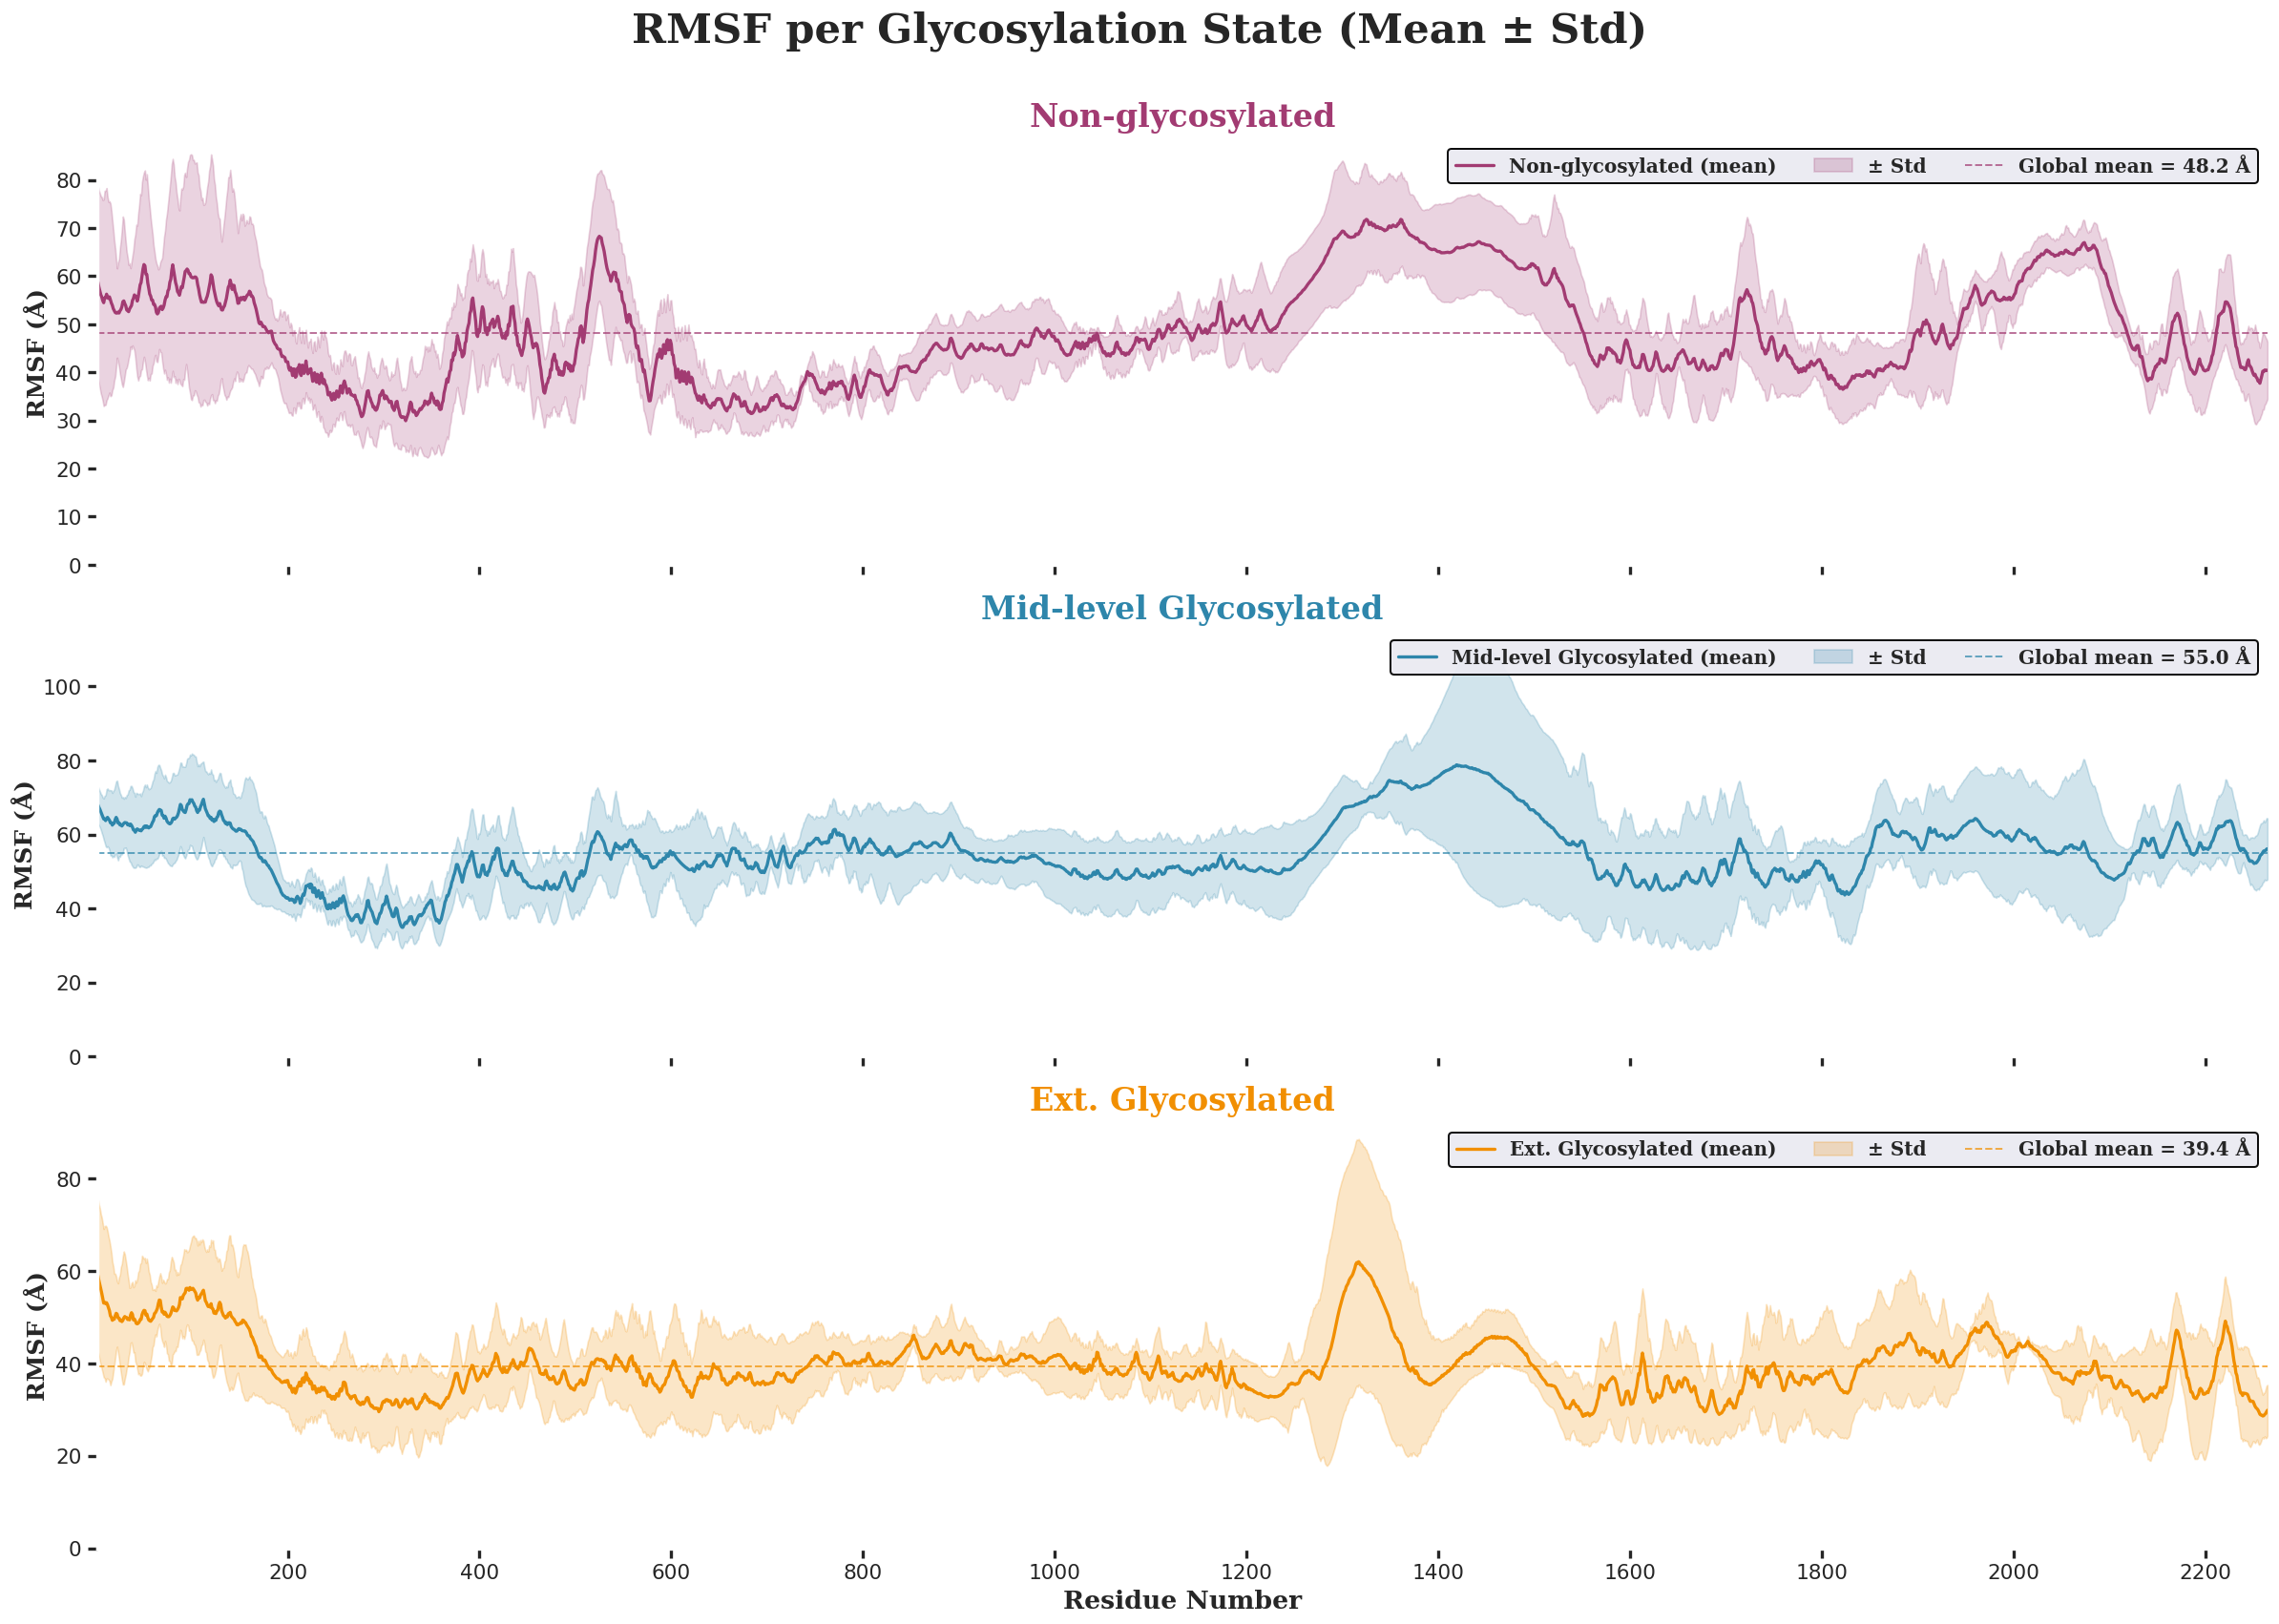

Saved: /home/computer2/analysis_simulations/analysis/plots/rmsf_3sys_individual_panels.png


In [10]:
# Full-protein RMSF: mean +/- std for all three systems overlaid
fig, ax = plt.subplots(figsize=(20, 6), dpi=120)
fig.set_facecolor("white")

systems = [
    (res_ng,  mean_ng,  std_ng,  CLR_NOG, "Non-glycosylated"),
    (res_g,   mean_g,   std_g,   CLR_GLY, "Mid-level Glycosylated"),
    (res_ext, mean_ext, std_ext, CLR_EXT, "Ext. Glycosylated"),
]

for x, mean, std, clr, lbl in systems:
    ax.plot(x, mean, linewidth=2.0, color=clr, label=lbl)
    ax.fill_between(x, mean - std, mean + std, alpha=0.18, color=clr)

ax.set_xlabel("Residue Number", fontsize=16, fontname="DejaVu Serif", fontweight="bold")
ax.set_ylabel("RMSF (\u00c5)", fontsize=16, fontname="DejaVu Serif", fontweight="bold")
ax.set_title("RMSF \u2014 All Three Glycosylation States",
             fontsize=24, fontname="DejaVu Serif", fontweight="bold", pad=14)
ax.set_xlim(res_ng.min(), res_ng.max())
ax.set_ylim(bottom=0)
ax.xaxis.set_major_locator(ticker.MultipleLocator(200))
ax.set_facecolor("white")
ax.spines["top"].set_visible(False);  ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(2.0); ax.spines["bottom"].set_linewidth(2.0)
ax.tick_params(labelsize=14, length=7, width=2.0, direction="out")
leg = ax.legend(fontsize=14, frameon=True, framealpha=0.95, edgecolor="black",
                prop={"family": "DejaVu Serif", "size": 14, "weight": "bold"},
                loc="upper right")
leg.get_frame().set_linewidth(1.2)
plt.tight_layout()
out = os.path.join(output_dir, "rmsf_3sys_full.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

# Separate panels: one per system, full residue range
fig, axes = plt.subplots(3, 1, figsize=(20, 14), dpi=120, sharex=True)
fig.set_facecolor("white")

for ax, (x, mean, std, clr, lbl) in zip(axes, systems):
    ax.plot(x, mean, linewidth=2.0, color=clr, label=f"{lbl} (mean)")
    ax.fill_between(x, mean - std, mean + std, alpha=0.22, color=clr,
                    label="\u00b1 Std")
    ax.axhline(mean.mean(), color=clr, linewidth=1.2,
               linestyle="--", alpha=0.7, label=f"Global mean = {mean.mean():.1f} \u00c5")
    ax.set_ylabel("RMSF (\u00c5)", fontsize=15, fontname="DejaVu Serif", fontweight="bold")
    ax.set_ylim(bottom=0)
    ax.set_xlim(x.min(), x.max())
    ax.set_facecolor("white")
    ax.spines["top"].set_visible(False);  ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(2.0); ax.spines["bottom"].set_linewidth(2.0)
    ax.tick_params(labelsize=13, length=6, width=2.0, direction="out")
    ax.xaxis.set_major_locator(ticker.MultipleLocator(200))
    leg = ax.legend(fontsize=12, frameon=True, framealpha=0.95, edgecolor="black",
                    prop={"family": "DejaVu Serif", "size": 12, "weight": "bold"},
                    loc="upper right", ncol=3)
    leg.get_frame().set_linewidth(1.2)
    ax.set_title(lbl, fontsize=20, fontname="DejaVu Serif",
                 fontweight="bold", color=clr, pad=8)

axes[-1].set_xlabel("Residue Number", fontsize=16,
                    fontname="DejaVu Serif", fontweight="bold")
fig.suptitle("RMSF per Glycosylation State (Mean \u00b1 Std)",
             fontsize=26, fontname="DejaVu Serif", fontweight="bold", y=1.01)
plt.tight_layout()
out2 = os.path.join(output_dir, "rmsf_3sys_individual_panels.png")
plt.savefig(out2, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out2}")


In [11]:
import os, pandas as pd, numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

CLR_NOG = "#A23B72"
CLR_GLY = "#2E86AB"
CLR_EXT = "#F18F01"

BASE    = "/home/computer2/analysis_simulations/analysis/rmsf/"
out_dir = "/home/computer2/analysis_simulations/analysis/plots/"
os.makedirs(out_dir, exist_ok=True)

def load_rmsf(folder, files):
    dfs = [pd.read_csv(BASE + folder + f, sep=r"\s+", skiprows=1,
                       names=["Res","RMSF"]).set_index("Res")["RMSF"]
           for f in files]
    combined = pd.concat(dfs, axis=1, keys=["R1","R2","R3"])
    return combined.mean(axis=1), combined.std(axis=1), combined.mean(axis=1).index

mean_ng,  std_ng,  res_ng  = load_rmsf("rmsf_noglyc/",
    ["longpts_noglyc1_rmsf.dat","longpts_noglyc2_rmsf.dat","longpts_noglyc3_rmsf.dat"])
mean_g,   std_g,   res_g   = load_rmsf("rmsf_midleve/",
    ["longpts_normal1_rmsf.dat","longpts_normal2_rmsf.dat","longpts_normal3_rmsf.dat"])
mean_ext, std_ext, res_ext = load_rmsf("rmsf_xglyc/",
    ["longpts_glyc1_rmsf.dat","longpts_glyc2_rmsf.dat","longpts_glyc3_rmsf.dat"])

print(f"Non-glycosylated     : {len(res_ng)} residues, res {res_ng.min():.0f}-{res_ng.max():.0f}, mean={mean_ng.mean():.2f} A")
print(f"Mid-level Glycosylated: {len(res_g)} residues, res {res_g.min():.0f}-{res_g.max():.0f}, mean={mean_g.mean():.2f} A")
print(f"Ext. Glycosylated     : {len(res_ext)} residues, res {res_ext.min():.0f}-{res_ext.max():.0f}, mean={mean_ext.mean():.2f} A")


Non-glycosylated     : 115 residues, res 1377-1491, mean=20.26 A
Mid-level Glycosylated: 115 residues, res 1377-1491, mean=16.00 A
Ext. Glycosylated     : 115 residues, res 1377-1491, mean=9.50 A


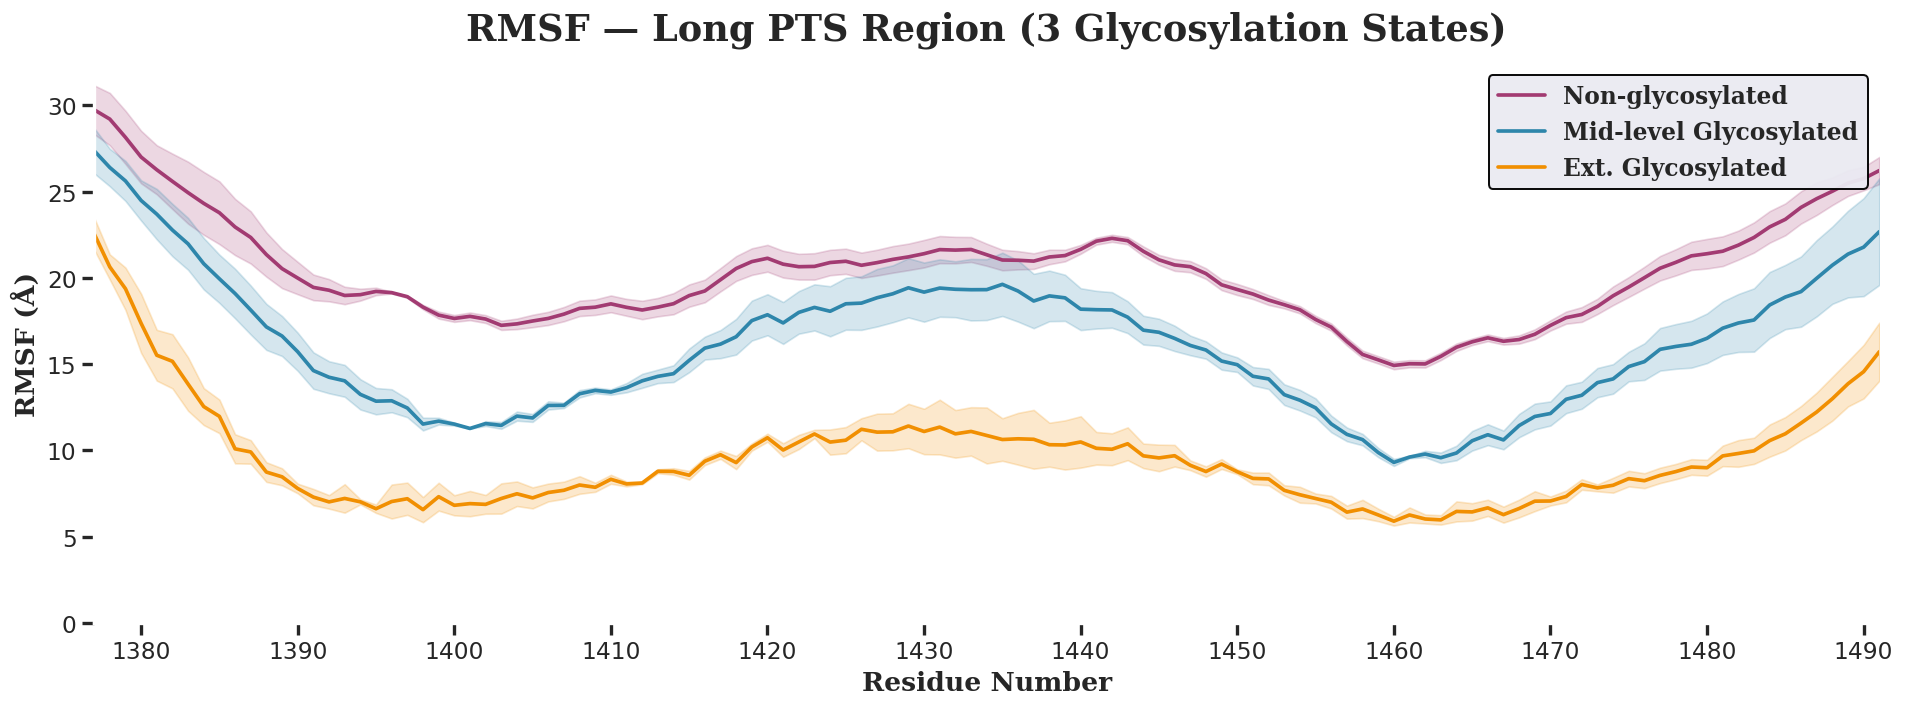

Saved: /home/computer2/analysis_simulations/analysis/plots/rmsf_longpts_3sys_overlay.png


In [12]:
fig, ax = plt.subplots(figsize=(16, 6), dpi=120)
fig.set_facecolor("white")

systems = [
    (res_ng,  mean_ng,  std_ng,  CLR_NOG, "Non-glycosylated"),
    (res_g,   mean_g,   std_g,   CLR_GLY, "Mid-level Glycosylated"),
    (res_ext, mean_ext, std_ext, CLR_EXT, "Ext. Glycosylated"),
]

for x, mean, std, clr, lbl in systems:
    ax.plot(x, mean, linewidth=2.2, color=clr, label=lbl)
    ax.fill_between(x, mean - std, mean + std, alpha=0.20, color=clr)

ax.set_xlabel("Residue Number", fontsize=16, fontname="DejaVu Serif", fontweight="bold")
ax.set_ylabel("RMSF (\u00c5)", fontsize=16, fontname="DejaVu Serif", fontweight="bold")
ax.set_title("RMSF \u2014 Long PTS Region (3 Glycosylation States)",
             fontsize=22, fontname="DejaVu Serif", fontweight="bold", pad=14)
ax.set_xlim(res_ng.min(), res_ng.max())
ax.set_ylim(bottom=0)
ax.xaxis.set_major_locator(ticker.MultipleLocator(10))
ax.set_facecolor("white")
ax.spines["top"].set_visible(False);  ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(2.0); ax.spines["bottom"].set_linewidth(2.0)
ax.tick_params(labelsize=14, length=7, width=2.0, direction="out")
leg = ax.legend(fontsize=14, frameon=True, framealpha=0.95, edgecolor="black",
                prop={"family":"DejaVu Serif","size":14,"weight":"bold"}, loc="upper right")
leg.get_frame().set_linewidth(1.2)
plt.tight_layout()
out = os.path.join(out_dir, "rmsf_longpts_3sys_overlay.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")


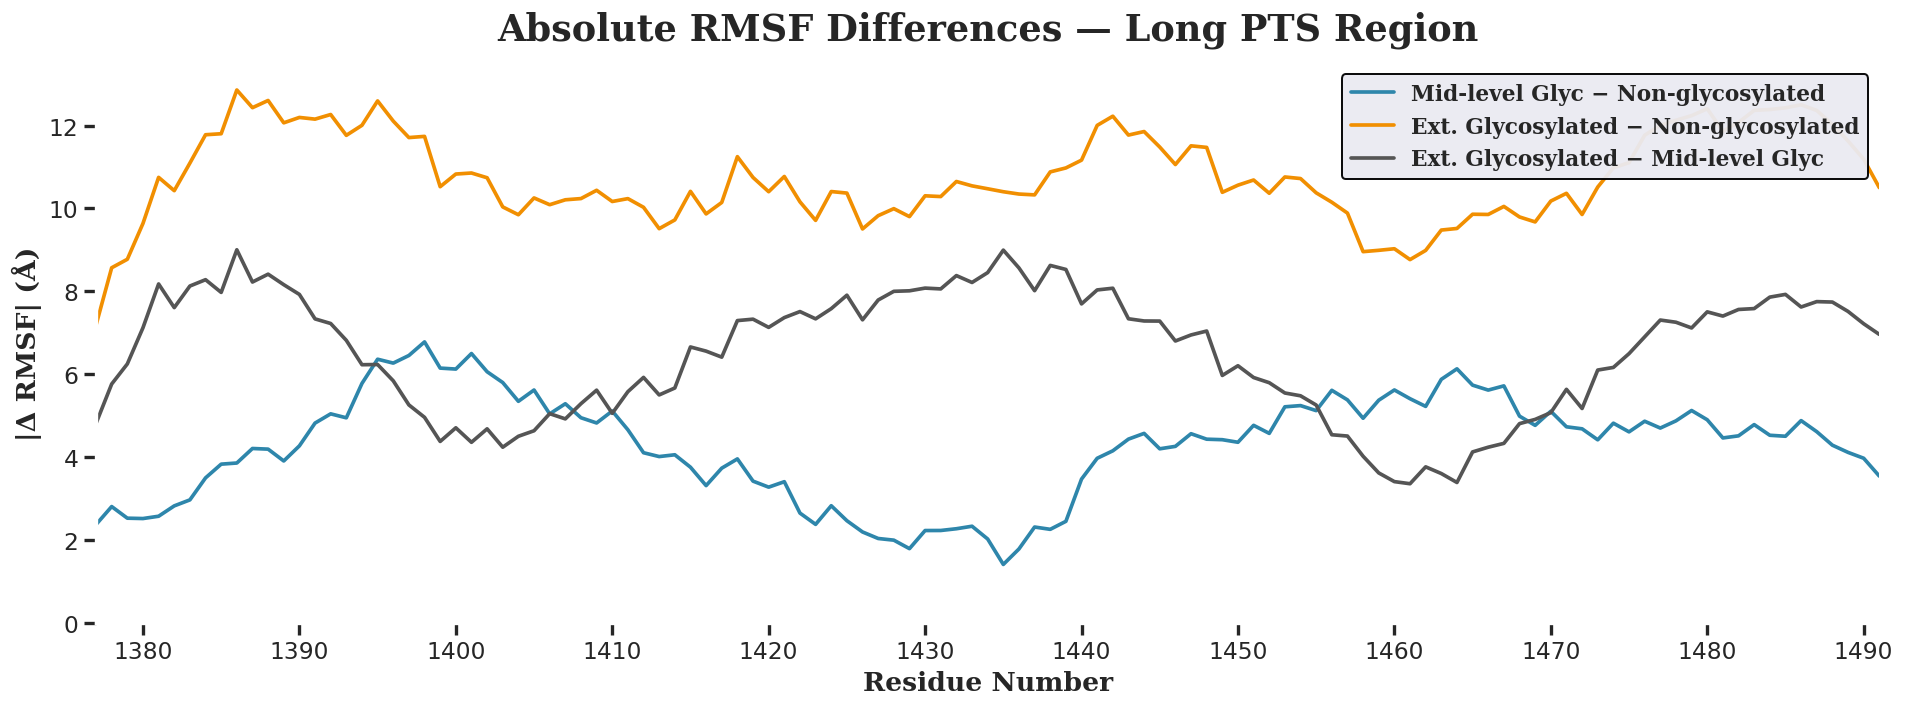

Saved: /home/computer2/analysis_simulations/analysis/plots/rmsf_longpts_abs_differences.png


In [13]:
import pandas as pd

RMSF_BASE = "/home/computer2/analysis_simulations/analysis/rmsf/"
CLR_NOG   = "#A23B72"
CLR_GLY   = "#2E86AB"
CLR_EXT   = "#F18F01"

def load_rmsf_pts(folder, files):
    dfs = [pd.read_csv(RMSF_BASE + folder + f, sep=r"\s+", skiprows=1,
                       names=["Res","RMSF"]).set_index("Res")["RMSF"] for f in files]
    combined = pd.concat(dfs, axis=1, keys=["R1","R2","R3"])
    return combined.mean(axis=1)

mean_nog = load_rmsf_pts("rmsf_noglyc/",
    ["longpts_noglyc1_rmsf.dat","longpts_noglyc2_rmsf.dat","longpts_noglyc3_rmsf.dat"])
mean_gly = load_rmsf_pts("rmsf_midleve/",
    ["longpts_normal1_rmsf.dat","longpts_normal2_rmsf.dat","longpts_normal3_rmsf.dat"])
mean_xgl = load_rmsf_pts("rmsf_xglyc/",
    ["longpts_glyc1_rmsf.dat","longpts_glyc2_rmsf.dat","longpts_glyc3_rmsf.dat"])

shared = sorted(set(mean_nog.index.astype(int))
              & set(mean_gly.index.astype(int))
              & set(mean_xgl.index.astype(int)))

nog_a = pd.Series(mean_nog.values, index=mean_nog.index.astype(int)).reindex(shared)
gly_a = pd.Series(mean_gly.values, index=mean_gly.index.astype(int)).reindex(shared)
xgl_a = pd.Series(mean_xgl.values, index=mean_xgl.index.astype(int)).reindex(shared)

diffs = [
    (np.abs(gly_a - nog_a), CLR_GLY,   "Mid-level Glyc \u2212 Non-glycosylated"),
    (np.abs(xgl_a - nog_a), CLR_EXT,   "Ext. Glycosylated \u2212 Non-glycosylated"),
    (np.abs(xgl_a - gly_a), "#555555", "Ext. Glycosylated \u2212 Mid-level Glyc"),
]

fig, ax = plt.subplots(figsize=(16, 6), dpi=120)
fig.set_facecolor("white")

for diff, clr, lbl in diffs:
    ax.plot(shared, diff.values, linewidth=2.2, color=clr, label=lbl)

ax.axhline(0, color="black", linewidth=1.2, linestyle="--", alpha=0.5)
ax.set_xlabel("Residue Number", fontsize=16, fontname="DejaVu Serif", fontweight="bold")
ax.set_ylabel("|\u0394 RMSF| (\u00c5)", fontsize=16, fontname="DejaVu Serif", fontweight="bold")
ax.set_title("Absolute RMSF Differences \u2014 Long PTS Region",
             fontsize=22, fontname="DejaVu Serif", fontweight="bold", pad=14)
ax.set_xlim(shared[0], shared[-1])
ax.set_ylim(bottom=0)
ax.xaxis.set_major_locator(ticker.MultipleLocator(10))
ax.set_facecolor("white")
ax.spines["top"].set_visible(False);  ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(2.0); ax.spines["bottom"].set_linewidth(2.0)
ax.tick_params(labelsize=14, length=7, width=2.0, direction="out")
leg = ax.legend(fontsize=13, frameon=True, framealpha=0.95, edgecolor="black",
                prop={"family":"DejaVu Serif","size":13,"weight":"bold"}, loc="upper right")
leg.get_frame().set_linewidth(1.2)
plt.tight_layout()
out = os.path.join(out_dir, "rmsf_longpts_abs_differences.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")
